In [17]:
# package Install LangGraph
!pip install langgraph

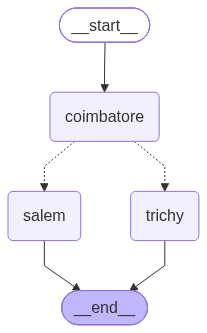

In [25]:
# import START, END, create edge use StateGraph
from langgraph.graph import START, END, StateGraph
# python TypedDict use type
from typing import TypedDict, Literal
import random

# Create State for edge
class JourneyState(TypedDict):
 current_location: str

# Create Functions to Node here
def coimbatore(state: JourneyState) -> JourneyState:
 print("9 Starting journey from Combatore")
 return {"current_location": "Departed from Combatore"}

def trichy(state: JourneyState) -> JourneyState:
 print("4 Arrived at Trichy")
 return {"current_location": "Visited Trichy"}

def salem(state: JourneyState) -> JourneyState:
 print ("& Arrived at Salem")
 return {"current_location": "Visited Salem"}
# decision maker any one place
def decide_intermediate_city(state:JourneyState) -> Literal["trichy", "salem"]:
 print(f" Diciding route... last update: {state['current_location']}")


 if random.random() < 0.5:
   print("-> Route selected: Trichy")
   return "trichy"
 else:
   print("--> Route selected: Salem")
   return "salem"


builder = StateGraph(JourneyState)
# connect Node here send two params (place, node)
builder.add_node("coimbatore", coimbatore)
builder.add_node("trichy", trichy)
builder.add_node("salem",salem)


# Connect Edge and Node
builder.add_edge(START, "coimbatore")


# this method conditional edge salem or trichy
builder.add_conditional_edges("coimbatore", decide_intermediate_city)
builder.add_edge("trichy", END)
builder.add_edge("salem", END)

graph = builder.compile()
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [26]:
graph.invoke({"current_location" : "Coimbatore"})

9 Starting journey from Combatore
 Diciding route... last update: Departed from Combatore
--> Route selected: Salem
& Arrived at Salem


{'current_location': 'Visited Salem'}

In [33]:
# Langchain message type
from langchain_core.messages import HumanMessage, AIMessage
messages = [AIMessage(content=f"So you said you were researching ocean mammals?", name="Model")]

messages.append(HumanMessage(content=f"Yes, that's right.", name="Lance"))


messages


[AIMessage(content='So you said you were researching ocean mammals?', additional_kwargs={}, response_metadata={}, name='Model', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content="Yes, that's right.", additional_kwargs={}, response_metadata={}, name='Lance')]

In [34]:
messages.append(AIMessage(content=f"Great, what would you like to learn about.", name="Mode?"))
messages.append(HumanMessage(content=f"I want to learn about the best place to see Orcas in the US.", name="Lance"))

messages


[AIMessage(content='So you said you were researching ocean mammals?', additional_kwargs={}, response_metadata={}, name='Model', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content="Yes, that's right.", additional_kwargs={}, response_metadata={}, name='Lance'),
 AIMessage(content='Great, what would you like to learn about.', additional_kwargs={}, response_metadata={}, name='Mode?', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='I want to learn about the best place to see Orcas in the US.', additional_kwargs={}, response_metadata={}, name='Lance')]

In [35]:
# Print All Messages
for m in messages:
 m.pretty_print()


================================== Ai Message ==================================
Name: Model

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Lance

Yes, that's right.
================================== Ai Message ==================================
Name: Mode?

Great, what would you like to learn about.
================================ Human Message =================================
Name: Lance

I want to learn about the best place to see Orcas in the US.


In [36]:
pip install langchain_groq


Note: you may need to restart the kernel to use updated packages.


In [37]:
import getpass
import os
if "GROQ_API_KEY" not in os.environ:
  os.environ["GROQ_API_KEY"] = getpass.getpass("Enter your Groq API key: ")


from langchain_groq import ChatGroq
#  i am choose model for OpenAI gpt-oss-120b
llm = ChatGroq(
  model="openai/gpt-oss-120b",
  temperature=0,
  max_tokens=None,
  reasoning_format="parsed",
  timeout=None,
  max_retries=2,
  # other params...
)

llm.invoke("Hi")

AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi". We need to respond appropriately. It\'s a simple greeting. We can respond friendly. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 45, 'prompt_tokens': 72, 'total_tokens': 117, 'completion_time': 0.097826693, 'completion_tokens_details': {'reasoning_tokens': 27}, 'prompt_time': 0.003548265, 'prompt_tokens_details': None, 'queue_time': 0.311510571, 'total_time': 0.101374958}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_5082008e34', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a11469-4c0b-7e13-9d34-c1f1fcb21b2d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 45, 'total_tokens': 117, 'output_token_details': {'reasoning': 27}})

In [39]:
# store var for this messages
res = llm.invoke(messages)


In [40]:
# check type
type(res)


langchain_core.messages.ai.AIMessage

In [41]:
# response Metadata check
res.response_metadata

{'token_usage': {'completion_tokens': 2454,
  'prompt_tokens': 127,
  'total_tokens': 2581,
  'completion_time': 5.10532097,
  'completion_tokens_details': {'reasoning_tokens': 32},
  'prompt_time': 0.005851317,
  'prompt_tokens_details': None,
  'queue_time': 0.317586199,
  'total_time': 5.111172287},
 'model_name': 'openai/gpt-oss-120b',
 'system_fingerprint': 'fp_87b3c396db',
 'service_tier': 'on_demand',
 'finish_reason': 'stop',
 'logprobs': None,
 'model_provider': 'groq'}